# NACA 2412 Airfoil with a 30 % Flap: Lift, Drag and Moment from XFOIL over the Second AIAA UQ Challenge Envelope

__Geoffrey Davis__, Aerospace Engineering, The Pennsylvania State University, University Park, PA 16802

__Ashwin Renganathan__, Aerospace Engineering and the Institute of Computational and Data Science (ICDS), The Pennsylvania State University, University Park, PA 16802

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook studies the low-fidelity model of Davis and Renganathan [[1]][R1]: XFOIL 6.99 [[3]][R3] for the NACA 2412 airfoil with a 30 % chord flap, set up as in the Second AIAA Uncertainty Quantification Challenge Problem for Aerodynamics [[2]][R2]. The paper is an **arXiv preprint** (arXiv:2606.28871v1, 27 June 2026); page, section and table numbers refer to it. The paper fits Gaussian-process surrogates to XFOIL and does not compute an active subspace. The data here are **stored data**: XFOIL runs made for this data set with the authors' XFOIL command sequence (from their repository [csdlpsu/uqchallenge2](https://github.com/csdlpsu/uqchallenge2)), plus the authors' own 98 training runs. XFOIL is not run in this notebook. The notebook needs Python 3 with numpy, scipy, matplotlib and [active_subspaces](https://github.com/paulcon/active_subspaces) version 1.0 or later, and runs in under a minute.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import generate_data as gd          # the design, bounds and seeds that wrote the files (no XFOIL is run here)

SEED = 2412                          # the only seed in this notebook (all bootstrap replicates)
t_start = time.perf_counter()

### Summary
XFOIL's lift, drag and quarter-chord moment of the flapped NACA 2412 are computed at 1000 Latin hypercube points over the challenge envelope (angle of attack $-5°$ to $10°$, flap $-5°$ to $15°$, Reynolds number $7\times10^5 \pm 0.5\,\%$); with the authors' convergence protocol 39 points fail, mostly because of XFOIL's default limit of 20 iterations rather than stall, and a retry ladder with 100 iterations converges 36 of them, leaving 3 (0.3 %). Lift and drag each have one dominant direction, a fixed mix of incidence and flap ($\lambda_1/\lambda_2 \approx 147$ and 67) whose flap-to-incidence ratio, 0.568, is below the 0.661 of thin-airfoil theory; the moment is driven mainly by the flap but needs a second variable ($\lambda_1/\lambda_2 \approx 13$; LOO $R^2$ at most 0.951 with one variable, 0.998 with two); and the Reynolds number is inactive, its effect over ±0.5 % too small for the data to resolve. Our extension also varies XFOIL's transition settings ($N_{crit}$ and two trip locations). It leaves the leading directions unchanged (cosines ≥ 0.9977), and the transition settings appear only in weaker second directions.

### Active subspaces in brief
For a function $f(\mathbf x)$ of $m$ inputs normalized to $[-1, 1]^m$ with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. When the first $n$ eigenvalues are much larger than the rest, $f$ changes mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, and a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend. Without gradients, $\nabla f$ is replaced by the gradient of a fitted model, here a global quadratic. The estimate is checked by bootstrap resampling and against estimators that make other assumptions. See Constantine [[4]][R4] and Constantine, Dow and Wang [[5]][R5].

### The model
**Airfoil and solver** (Sec. 1.1, p. 2; Sec. 1.2.1, p. 3). The NACA 2412 airfoil has a 30 % chord plain flap. The challenge's nominal Reynolds number is 700,000 at sea level, so the flow is incompressible. XFOIL couples a 2-D panel method with an integral boundary-layer model and $e^N$ transition prediction [[3]][R3]. The paper uses "XFOIL v6.99 with a 100-panel baseline setup that accompanied the challenge problem". The authors' code (`uqlib.py`, class `XFOIL`, commit `73eaec9`) gives the full command sequence, used here unchanged:

| step | XFOIL commands | meaning |
|---|---|---|
| geometry | `NACA 2412` | built-in 4-digit airfoil |
| flap | `GDES` → `FLAP` 0.70, 999, 0.5, $\beta$ → `EXEC` | hinge at x/c = 0.70, halfway through the local thickness; deflection $\beta$ in degrees, + down |
| panels | `PPAR` → `N` 100 | 100 panel nodes |
| flow | `OPER` → `MACH` 0, `VISC` Re, `VPAR` → `N` 0.01 | incompressible, viscous, transition exponent $N_{crit} = 0.01$ |
| solve | `PACC`, `ALFA` $\alpha$ | one angle of attack; default 20 viscous iterations (100 in our retry ladder) |

$N_{crit} = 0.01$ (XFOIL's default is 9) puts transition within 4.2 % of the chord from the leading edge on both sides (next cells). In effect the boundary layer is turbulent almost everywhere. The paper does not discuss this setting; it says only that "the internal XFOIL settings are fixed" (p. 5).

**Convergence.** "For cases at higher flap angles or angles of attack, where XFOIL may fail to converge, we incorporated a driver that first accumulates converged solutions at lower angles of attack for the same flap setting and then continues toward the desired condition" (p. 3). The authors' `xfoil_training.py` first tries $\alpha$ directly. If that fails, it starts a new XFOIL process and steps through $\alpha$ = 0, 1, 2, … before the target (status 1 below). For $\alpha \le 0$ that sweep is empty, so we add a third attempt with the same unit steps from 0 down to $\alpha$ (status 2, our addition). All three attempts keep XFOIL's default limit of 20 viscous iterations. Most points that fail them are not stalled: with $N_{crit} = 0.01$ transition sits at the leading edge, and the Newton iteration there can settle into a limit cycle (in XFOIL's trace for a failed point at α = −2.46°, β = −2.94°, the largest residual is at boundary-layer station 3 in all 20 iterations; DATA.md). So we add a **retry ladder**, used only when attempts 1–3 all fail, which leaves every point they converge unchanged: status 3 is `ITER 100` (100 iterations) with $\alpha$ directly; status 4 is an `ITER 100` continuation from the nearest integer angle that converges (on the side towards 0 first, as on the authors' path), in steps of 0.5° (0.25° when α > 7° and β > 10°), halving a step that fails down to 1/16°. The `xfoil_run.py` docstring gives the exact rule, and `convergence_ladder.csv` records each path. A point that fails all attempts is kept in the files with `nan` outputs and status −1. Only the target angle is read as the answer (attempts 1–4 write only it to XFOIL's polar file; the continuation requires every angle of its path to have converged, in order), so a converged intermediate angle cannot be mistaken for the answer.

**Quantities of interest** (Sec. 1.1, Table 1): the lift coefficient $C_l$, the drag coefficient $C_d$ and the quarter-chord pitching-moment coefficient $C_m$, all dimensionless, each a scalar per run, with no transformation. XFOIL's polar file prints $C_l$ and $C_m$ to 4 decimals and $C_d$ to 5. Those are the digits in `outputs.csv`.

**Inputs.** The challenge study varies the three inputs of the paper's training design (Sec. 1.2.1, p. 3: "angle of attack from −5° to 10°, flap angle from −5° to 15°, and Reynolds number from 665000 to 735000"). **The paper's printed Reynolds range does not match its code; we use the code's range, ±0.5 %.** The code (`xfoil_training.py`, `uqlib.DEFAULT_BOUNDS`) uses $7\times10^5 \times [0.995, 1.005]$ = [696,500, 703,500]; the printed 665,000–735,000 is ±5 %, ten times wider, and the same text is in the authors' AIAA Journal source (`main_aiaa_journal.tex`, line 168). Four things point to the code's range: the authors' 98 training rows occupy 98 different strata of a 100-point Latin hypercube on ±0.5 % but only 10 on ±5 % (printed in the comparison section), so their design was drawn on ±0.5 %; the paper's own Tables 3–5 (p. 23) bound the latent Re by 696,500 and 703,500; Table 1 (p. 2) gives the truth data's input uncertainty as Re ± 3500; and the challenge's truth files in the authors' repository give no other Re interval. The printed range is most likely a factor-10 misprint (an open question for the authors). A small labelled check runs XFOIL at the printed range too (`re_sensitivity.csv`, below). The input table below is printed from `generate_data.py`.

In [2]:
nominal = {'alpha': 'none (operating condition)', 'flap': 'none (operating condition)', 'Re': '7.0e5',
           'ncrit': '0.01 (challenge)', 'xtr_top': '1.0 = no trip (challenge)', 'xtr_bot': '1.0 = no trip (challenge)'}
desc = {'alpha': 'angle of attack', 'flap': 'flap deflection, + trailing edge down', 'Re': 'chord Reynolds number',
        'ncrit': 'e^N transition amplification exponent', 'xtr_top': 'forced-transition (trip) x/c, upper side',
        'xtr_bot': 'forced-transition (trip) x/c, lower side'}
print(f"{'study':10s} {'name':8s} {'description':40s} {'units':5s} {'lower':>10s} {'upper':>10s}  nominal")
for study, bounds in [('challenge', gd.PRIMARY_BOUNDS), ('extension', gd.EXTENSION_BOUNDS[3:])]:
    for name, units, lo, hi in bounds:
        print(f'{study:10s} {name:8s} {desc[name]:40s} {units:5s} {lo:10.4g} {hi:10.4g}  {nominal[name]}')
print(f'design: Latin hypercube, M = {gd.M_PRIMARY} (seed {gd.SEED_PRIMARY}) and M = {gd.M_EXTENSION} (seed {gd.SEED_EXTENSION})')

study      name     description                              units      lower      upper  nominal
challenge  alpha    angle of attack                          deg           -5         10  none (operating condition)
challenge  flap     flap deflection, + trailing edge down    deg           -5         15  none (operating condition)
challenge  Re       chord Reynolds number                    -      6.965e+05  7.035e+05  7.0e5
extension  ncrit    e^N transition amplification exponent    -           0.01          9  0.01 (challenge)
extension  xtr_top  forced-transition (trip) x/c, upper side x/c         0.05          1  1.0 = no trip (challenge)
extension  xtr_bot  forced-transition (trip) x/c, lower side x/c         0.05          1  1.0 = no trip (challenge)
design: Latin hypercube, M = 1000 (seed 2412) and M = 1000 (seed 24120)


**Our extension (m = 6).** With $m = 3$ and an almost inert Reynolds number, the challenge's subspace is close to a 2-D problem. To test whether XFOIL settings the challenge holds fixed change the picture, a second design also varies three transition settings, independently and uniformly: $N_{crit} \in [0.01, 9]$, from the challenge's value up to XFOIL's default for a quiet wind tunnel, and forced-transition (trip) locations on the upper and lower surfaces, $x_{tr}/c \in [0.05, 1]$, where 1 means no trip, the challenge's setting. These ranges are our choice, not the paper's or the challenge's. Where $N_{crit}$ is near 0.01, natural transition comes at the leading edge, before any trip at $x/c \ge 0.05$, so over that part of the box the trip inputs have no effect; this shapes the weights of the trip locations in the $m = 6$ eigenvectors. The extension is reported separately and does not change the challenge study.

### Load data
All files are CSVs with two `#` lines. `inputs.csv` and `outputs.csv` hold the challenge study, and `extension_inputs.csv` and `extension_outputs.csv` our extension, with inputs in physical units (degrees; Re). `reference_points.csv` holds XFOIL at the challenge's 7 calibration and 4 prediction points. `davis_training_98.csv` is the authors' training file, copied as text, and `davis_rerun_outputs.csv` holds our XFOIL at the authors' 98 inputs.

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')                     # alpha (deg), flap (deg), Re
Y = np.loadtxt('outputs.csv', delimiter=',')                    # CL, CD, CDp, CM, xtr_top, xtr_bot, status
Xe = np.loadtxt('extension_inputs.csv', delimiter=',')          # + Ncrit, trip x/c upper, trip x/c lower
Ye = np.loadtxt('extension_outputs.csv', delimiter=',')
Ref = np.loadtxt('reference_points.csv', delimiter=',')          # set, alpha, flap, Re, then as outputs.csv
Dv = np.loadtxt('davis_training_98.csv', delimiter=',')          # the authors' file: Re, alpha, flap, CL, CD, CM
Dr = np.loadtxt('davis_rerun_outputs.csv', delimiter=',')        # this XFOIL at the authors' 98 inputs
Rs = np.loadtxt('re_sensitivity.csv', delimiter=',')             # Table 1 points at 5 Reynolds numbers
Lad = np.loadtxt('convergence_ladder.csv', delimiter=',', ndmin=2)  # file, row, status, continuation path
print('challenge study', X.shape, Y.shape, '| extension', Xe.shape, Ye.shape,
      '| reference points', Ref.shape, '| authors\' file', Dv.shape, '| rerun', Dr.shape,
      '| Re check', Rs.shape, '| ladder log', Lad.shape)

challenge study (1000, 3) (1000, 7) | extension (1000, 6) (1000, 7) | reference points (11, 11) | authors' file (98, 6) | rerun (98, 7) | Re check (35, 10) | ladder log (47, 8)


The next cell checks the design and counts convergence failures and values without physical meaning. **Rule:** rows with status −1 (no convergence, `nan`) are dropped in this notebook. Rows that converged only in a sweep (status 1 or 2) or in the retry ladder (status 3 or 4) are kept, flagged in the plots, and tested below by leaving them out.

In [4]:
names = [b[0] for b in gd.PRIMARY_BOUNDS]
lo = np.array([b[2] for b in gd.PRIMARY_BOUNDS]); hi = np.array([b[3] for b in gd.PRIMARY_BOUNDS])
st = Y[:, 6].astype(int)
print('inside the box:', bool(np.all((X >= lo) & (X <= hi))), '; inputs.csv redrawn from the seed:',
      np.array_equal(X, gd.latin_hypercube(gd.M_PRIMARY, gd.PRIMARY_BOUNDS, gd.SEED_PRIMARY)))
STATUS = [(0, 'converged directly'), (1, "converged in the authors' 0, 1, 2, ... sweep"),
          (2, 'converged in our sweep towards negative alpha'), (3, 'converged directly with ITER 100 (retry ladder)'),
          (4, 'converged in an ITER 100 continuation (retry ladder)'), (-1, 'did not converge (nan)')]
for s, lab in STATUS:
    print(f'  status {s:2d}: {np.sum(st == s):4d}  {lab}')
fail = st < 0
f13 = fail | (st >= 3)                                             # failed the protocol without the ladder
hl = (X[:, 0] > 5) & (X[:, 1] > 10)
print(f'failed attempts 1-3 (XFOIL default of 20 iterations): {f13.sum()}; '
      f'{np.sum(f13 & hl)} of them in the corner alpha > 5 deg, flap > 10 deg ({hl.sum()} design points)')
lad0 = Lad[Lad[:, 0] == 0]
seq = lad0[lad0[:, 2] == 4]
print(f'continuations (row: start -> alpha, smallest step): ' + ', '.join(
    f'{int(r[1])}: {r[4]:.0f} -> {X[int(r[1]), 0]:.3f} deg, {r[5]:g}' for r in seq))
print(f'largest CL of the ladder rows {Y[st >= 3, 0].max():.4f}; largest CL of all converged rows {np.nanmax(Y[:, 0]):.4f}')
print(f'remaining failures ({fail.sum()}; row: alpha, flap, Re): ' +
      ', '.join(f'{i}: ({X[i, 0]:.3f}, {X[i, 1]:.3f}, {X[i, 2]:.0f})' for i in np.where(fail)[0]))
ok = ~fail
print(f'all outputs finite where status >= 0: {bool(np.all(np.isfinite(Y[ok, :6])))};  nan everywhere else: '
      f'{bool(np.all(np.isnan(Y[fail, :6])))}')
print(f'CD > 0 in every converged run: {bool(np.all(Y[ok, 1] > 0))};  transition x/c in [0, 1]: '
      f'{bool(np.all((Y[ok, 4:6] >= 0) & (Y[ok, 4:6] <= 1)))} (max {Y[ok, 4:6].max():.4f})')
print(f'negative pressure drag CDp (an XFOIL bookkeeping value CD - CDf, not used below): '
      f'{np.sum(Y[ok, 2] < 0)} runs, min {Y[ok, 2].min():.5f}')
print(f'ranges: CL [{Y[ok, 0].min():.4f}, {Y[ok, 0].max():.4f}], CD [{Y[ok, 1].min():.5f}, {Y[ok, 1].max():.5f}], '
      f'CM [{Y[ok, 3].min():.4f}, {Y[ok, 3].max():.4f}]')
Xk, Yk, stk = X[ok], Y[ok], st[ok]
print(f'rule: drop the {fail.sum()} rows with status -1; keep {ok.sum()} rows')

inside the box: True ; inputs.csv redrawn from the seed: True
  status  0:  816  converged directly
  status  1:  133  converged in the authors' 0, 1, 2, ... sweep
  status  2:   12  converged in our sweep towards negative alpha
  status  3:   35  converged directly with ITER 100 (retry ladder)
  status  4:    1  converged in an ITER 100 continuation (retry ladder)
  status -1:    3  did not converge (nan)
failed attempts 1-3 (XFOIL default of 20 iterations): 39; 21 of them in the corner alpha > 5 deg, flap > 10 deg (80 design points)
continuations (row: start -> alpha, smallest step): 12: 5 -> 5.142 deg, 0.0625
largest CL of the ladder rows 1.6200; largest CL of all converged rows 1.6405
remaining failures (3; row: alpha, flap, Re): 370: (-2.456, -2.943, 699921), 552: (3.835, 7.906, 700460), 893: (-2.048, -4.254, 697595)
all outputs finite where status >= 0: True;  nan everywhere else: True
CD > 0 in every converged run: True;  transition x/c in [0, 1]: True (max 0.0419)
negative pres

Of the 1000 runs, 816 converge directly, 133 need the authors' sweep and 12 need our negative-$\alpha$ sweep. 39 fail all three attempts with XFOIL's default 20 iterations, 21 of them in the corner $\alpha > 5°$, $\beta > 10°$ (80 design points). The retry ladder converges 35 of the 39 directly with `ITER 100` and one more (row 12, α = 5.142°) in a continuation from 5°. These points are not post-stall: the largest $C_l$ among them, 1.6200, is below the largest in the file, 1.6405. Three points (0.3 %) still fail: two at negative α and β, (−2.456°, −2.943°) and (−2.048°, −4.254°), and one at (3.835°, 7.906°), all at moderate lift. They are isolated XFOIL non-convergences, not stall. The authors' file has 98 rows from a 100-point design (`num = 100`, failures skipped), so their failure rate was probably 2 %. Every converged run has $C_d > 0$, and transition lies within $x/c \le 0.0419$, as $N_{crit} = 0.01$ implies. One run has a slightly negative pressure drag $C_{d,p} = -0.00108$. That is XFOIL's bookkeeping value $C_d - C_{d,f}$, not used here, and the row is kept.

### Estimate the subspace
**Why no gradients.** XFOIL gives no derivatives. Finite differences are cheap here, but XFOIL prints only 4 decimals of $C_l$. A central difference with a step of 1 % of the $\alpha$ range would be accurate to about half a percent. The Reynolds number, however, changes $C_l$ by only about $4\times10^{-4}$ over its whole range in direct XFOIL runs (printed below), so a 1 % step in Re would change $C_l$ by about $4\times10^{-6}$, far below the printed digits: that derivative would be pure noise. Failed points would also break finite-difference stencils. We therefore use values only.

**Estimator.** The library's global quadratic estimator (`estimator="qphd"`) fits $q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12\mathbf x^T\mathbf H\mathbf x$ by least squares on the 10 monomials of degree ≤ 2 in the 3 normalized inputs. It returns $\mathbf C = \mathbf g\mathbf g^T + \tfrac13\mathbf H^2$, which is exactly $\mathbb E[\nabla q\,\nabla q^T]$ for the uniform density on the cube [[4]][R4]. With 997 runs, the fit has about 100 runs per coefficient, far above the factor of 2 we require (20 runs). The library warns (`ValidityWarning`, silenced here) that reading $\mathbf g$ and $\mathbf H$ as the average gradient and Hessian of $f$ needs Gaussian inputs (Li [[6]][R6]). The matrix is still the active subspace of the fitted quadratic, so the next cells check it against local linear gradients (OPG), least squares (OLS) and the directly converged runs alone. The inputs are independent uniforms on the box, the distribution a Latin hypercube samples. The space normalizes each input by its own half-range, and the physical inputs are passed unscaled. The bootstrap resamples the runs 500 times with one seed (`SEED`). Signs: each $w_1$ and $w_2$ is oriented so that its active variable is positively correlated with the QoI (`ac.orient(by="covariance")`).

In [5]:
space = ac.Uniform(lo, hi, names=names)
qois = {'CL': 0, 'CD': 1, 'CM': 3}
labels = {'CL': '$C_l$', 'CD': '$C_d$', 'CM': '$C_m$ (quarter chord)'}
res, quad = {}, {}
for q, j in qois.items():
    f = Yk[:, j]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ac.ValidityWarning)
        s = ac.active_subspace(space=space, X=Xk, f=f, estimator='qphd', nboot=500, bootstrap_vectors=2,
                               rng=SEED, qoi=q)
    res[q] = ac.orient(s, by='covariance', X=Xk, f=f, columns=2)     # w1, w2 increase with the QoI
    quad[q] = ac.fit_surrogate(X=Xk, f=f, space=space, subspace=None, kind='poly', degree=2, qoi=q)
    lam = res[q].eigenvalues
    lo95, hi95 = np.percentile(res[q].bootstrap_eigenvalues, [2.5, 97.5], axis=0)
    ks, crit, khat = ac.dimension_criterion(res[q], rule='evg')
    print(f'{q}: quadratic fit LOO R^2 {quad[q].loo_r_squared:.5f};  eigenvalues {np.array2string(lam, precision=3)};  '
          f'lam1/lam2 = {lam[0] / lam[1]:.1f}, lam2/lam3 = {lam[1] / lam[2]:.0f};  EVG picks n = {khat}')
    print(f'     95 % bootstrap ranges: ' + ', '.join(f'[{a:.3g}, {b:.3g}]' for a, b in zip(lo95, hi95)))

CL: quadratic fit LOO R^2 0.99921;  eigenvalues [8.168e-01 5.541e-03 9.548e-07];  lam1/lam2 = 147.4, lam2/lam3 = 5804;  EVG picks n = 1
     95 % bootstrap ranges: [0.812, 0.823], [0.0052, 0.00591], [9.19e-08, 1.46e-05]


CD: quadratic fit LOO R^2 0.98865;  eigenvalues [2.099e-04 3.132e-06 1.044e-09];  lam1/lam2 = 67.0, lam2/lam3 = 2999;  EVG picks n = 1
     95 % bootstrap ranges: [0.000203, 0.000217], [2.74e-06, 3.57e-06], [3.52e-10, 4.01e-08]


CM: quadratic fit LOO R^2 0.99810;  eigenvalues [6.130e-03 4.561e-04 1.119e-08];  lam1/lam2 = 13.4, lam2/lam3 = 40767;  EVG picks n = 1
     95 % bootstrap ranges: [0.00608, 0.00618], [0.000434, 0.000478], [8.56e-10, 3.02e-07]


A quadratic in the three inputs predicts all three coefficients well: LOO $R^2$ = 0.99921 for $C_l$, 0.98865 for $C_d$ and 0.99810 for $C_m$. Each spectrum has one large gap, $\lambda_1/\lambda_2$ = 147.4, 67.0 and 13.4, and the eigenvalue-gap rule picks $n = 1$ for all three. The bootstrap ranges of $\lambda_1$ and $\lambda_2$ are far apart in each case. The third eigenvalue is smaller than the second by a factor of at least 2999 (5804, 2999 and 40767). The third direction is the Reynolds number (below): the challenge's 3-input problem is in practice a 2-input one. How much these ratios depend on the treatment of failed runs is tested after the sufficient summary plots; in short, they move by at most 4 %, so we quote them as about 147, 67 and 13.

In [6]:
Zk = 2 * (Xk - lo) / (hi - lo) - 1                                # normalized inputs, as the library uses
chk = {}
for q, j in qois.items():
    f = Yk[:, j]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ac.ValidityWarning)
        opg = ac.active_subspace(space=space, X=Xk, f=f, estimator='opg', n=1)
        ols = ac.active_subspace(space=space, X=Xk, f=f, estimator='ols', n=1)
        d0 = stk == 0
        s0 = ac.active_subspace(space=space, X=Xk[d0], f=f[d0], estimator='qphd', n=1)
        d2 = stk <= 2
        s2 = ac.active_subspace(space=space, X=Xk[d2], f=f[d2], estimator='qphd', n=1)
    w = res[q].eigenvectors
    chk[q] = dict(opg=opg, ols=ols, s0=s0, s2=s2)
    print(f'{q}: |w1.w1_opg| {abs(w[:, 0] @ opg.eigenvectors[:, 0]):.4f} (OPG lam1/lam2 {opg.eigenvalues[0] / opg.eigenvalues[1]:.0f});  '
          f'|w1.w_ols| {abs(w[:, 0] @ ols.eigenvectors[:, 0]):.4f};  status-0 rows only ({d0.sum()}): '
          f'|w1.w1| {abs(w[:, 0] @ s0.eigenvectors[:, 0]):.5f};  without the ladder rows ({d2.sum()}): '
          f'|w1.w1| {abs(w[:, 0] @ s2.eigenvectors[:, 0]):.6f}, lam1/lam2 {s2.eigenvalues[0] / s2.eigenvalues[1]:.1f}')

CL: |w1.w1_opg| 1.0000 (OPG lam1/lam2 90);  |w1.w_ols| 0.9998;  status-0 rows only (816): |w1.w1| 1.00000;  without the ladder rows (961): |w1.w1| 1.000000, lam1/lam2 145.5
CD: |w1.w1_opg| 0.9998 (OPG lam1/lam2 26);  |w1.w_ols| 0.9999;  status-0 rows only (816): |w1.w1| 0.99984;  without the ladder rows (961): |w1.w1| 0.999994, lam1/lam2 68.5


CM: |w1.w1_opg| 0.9989 (OPG lam1/lam2 5);  |w1.w_ols| 0.9950;  status-0 rows only (816): |w1.w1| 0.99999;  without the ladder rows (961): |w1.w1| 0.999999, lam1/lam2 13.7


All checks agree on the first direction. Local linear gradients (OPG) give $|w_1\cdot w|$ = 1.0000, 0.9998 and 0.9989, and least squares (OLS) 0.9998, 0.9999 and 0.9950, for $C_l$, $C_d$ and $C_m$. OPG's eigenvalue ratios are smaller (90, 26, 5) because local fits on noisy, rounded values spread a little variance into the other directions. Using only the 816 directly converged runs changes $w_1$ by at most $1 - 0.99984$ (for $C_d$), and leaving out the 36 runs converged by the retry ladder changes it by at most $1 - 0.999994$, so neither the sweep-converged nor the ladder runs bend the result. Without the ladder runs (961 rows, the data before the ladder) the ratios are 145.5, 68.5 and 13.7.

**The Reynolds number.** Is its weight in the eigenvectors physical? The next cell gives the quadratic fit's change of each QoI across the Re range, with its standard error, and compares it with XFOIL run directly at the 7 calibration points of Table 1 (`re_sensitivity.csv`). That file also has the paper's printed range, 665,000–735,000: a labelled sensitivity check, not a design.

In [7]:
# Reynolds number: the quadratic's Re terms with their standard errors (OLS on the 10 monomials of the
# normalized inputs, the same least-squares problem as the 'qphd' fit), against XFOIL run directly
def mono(Z):
    m = Z.shape[1]
    return np.column_stack([np.ones(len(Z))] + [Z[:, i] for i in range(m)] +
                           [Z[:, i] * Z[:, j] for i in range(m) for j in range(i, m)])
A = mono(Zk)                       # columns: 1, a, b, R, aa, ab, aR, bb, bR, RR
AtAi = np.linalg.inv(A.T @ A)
z55 = 2 * (np.array([5.0, 5.0]) - lo[:2]) / (hi[:2] - lo[:2]) - 1  # (alpha, flap) = (5, 5) deg, normalized
re_fit = {}
for q, j in qois.items():
    c = AtAi @ A.T @ Yk[:, j]
    r = Yk[:, j] - A @ c
    cov = (r @ r / (len(r) - A.shape[1])) * AtAi
    for lab, g in [('mid-range alpha, flap', np.eye(10)[3]), ('(5, 5) deg', np.eye(10)[3] + z55[0] * np.eye(10)[6] + z55[1] * np.eye(10)[8])]:
        d, se = 2 * g @ c, 2 * np.sqrt(g @ cov @ g)        # change from Re = 696,500 to 703,500
        re_fit[q, lab] = (d, se)
        print(f'{q}: quadratic fit, change over the Re range at {lab}: {d:+.2e} +- {se:.1e} (1 SE; |change|/SE = {abs(d) / se:.1f})')
# XFOIL directly at the 7 calibration points of Table 1: re_sensitivity.csv
print('XFOIL at the 7 Table 1 points (alpha, flap): change in CL, CD, CM from Re = 696,500 to 703,500 | from 665,000 to 735,000')
pts = Rs[Rs[:, 2] == 7e5][:, :2]
dRe = {}
for a, b in pts:
    row = lambda re: Rs[(Rs[:, 0] == a) & (Rs[:, 1] == b) & (Rs[:, 2] == re)][0]
    d1 = row(703500.0)[[3, 4, 6]] - row(696500.0)[[3, 4, 6]]
    d5 = row(735000.0)[[3, 4, 6]] - row(665000.0)[[3, 4, 6]]
    dRe[a, b] = (d1, d5)
    print(f'  ({a:3.0f}, {b:3.0f}):  {d1[0]:+.4f} {d1[1]:+.5f} {d1[2]:+.4f}  |  {d5[0]:+.4f} {d5[1]:+.5f} {d5[2]:+.4f}')
print('Re check statuses:', {int(k): int(v) for k, v in zip(*np.unique(Rs[:, 9], return_counts=True))},
      '; Re = 700,000 rows equal reference_points.csv:',
      np.array_equal(Rs[Rs[:, 2] == 7e5][:, 3:], Ref[Ref[:, 0] == 0][:, 4:]))
d5 = np.array([v[1] for v in dRe.values()])
gal = 0.5 * (hi[0] - lo[0]) * np.mean(np.abs(np.diff(Rs[Rs[:, 2] == 7e5][[0, 1, 2], 3]))) / 5.0   # half-range * dCL/dalpha
print(f'over +-5 %: max |dCL| {abs(d5[:, 0]).max():.4f}; normalized alpha-derivative of CL at flap 0: {gal:.3f}; '
      f'(max |dCL| / 2 / that)^2 = {(abs(d5[:, 0]).max() / 2 / gal) ** 2:.1e}')

CL: quadratic fit, change over the Re range at mid-range alpha, flap: -1.05e-03 +- 1.5e-03 (1 SE; |change|/SE = 0.7)
CL: quadratic fit, change over the Re range at (5, 5) deg: -2.10e-03 +- 1.7e-03 (1 SE; |change|/SE = 1.2)
CD: quadratic fit, change over the Re range at mid-range alpha, flap: +7.54e-05 +- 7.8e-05 (1 SE; |change|/SE = 1.0)
CD: quadratic fit, change over the Re range at (5, 5) deg: +1.56e-04 +- 8.9e-05 (1 SE; |change|/SE = 1.8)
CM: quadratic fit, change over the Re range at mid-range alpha, flap: -4.93e-06 +- 2.1e-04 (1 SE; |change|/SE = 0.0)
CM: quadratic fit, change over the Re range at (5, 5) deg: +4.81e-05 +- 2.4e-04 (1 SE; |change|/SE = 0.2)
XFOIL at the 7 Table 1 points (alpha, flap): change in CL, CD, CM from Re = 696,500 to 703,500 | from 665,000 to 735,000
  (  0,   0):  +0.0001 -0.00003 +0.0000  |  +0.0008 -0.00024 -0.0001
  (  5,   0):  +0.0002 -0.00003 +0.0000  |  +0.0019 -0.00029 -0.0003
  ( 10,   0):  +0.0006 -0.00005 -0.0001  |  +0.0055 -0.00046 -0.0008
  (

**The data cannot resolve the Reynolds effect over ±0.5 %.** The quadratic's change in $C_l$ across the range is $-1.05\times10^{-3} \pm 1.5\times10^{-3}$ (1 SE) at mid-range α and β, and $-2.10\times10^{-3} \pm 1.7\times10^{-3}$ at (5°, 5°): zero within 1.2 SE, and of the wrong sign. XFOIL run directly gives $+0.0004$ at (5°, 5°) over the same range, and between $-0.0002$ and $+0.0006$ at the 7 points, at the level of its printed digits. Over the paper's printed ±5 % range XFOIL resolves the effect: $C_l$ rises by 0.0008–0.0055 at the six points with $\alpha, \beta \ge 0$ (+0.0043 at (5°, 5°)) and falls by 0.0016 at (−5°, −5°), with $C_d$ lower by 0.00024–0.00046. Even over ±5 %, the largest change, 0.0055, set against the normalized α-derivative of $C_l$ (0.759) gives Re an eigenvalue weight of order $(0.0055/2/0.759)^2 = 1.3\times10^{-5}$ of $\lambda_1$. So the conclusion "Re is inactive" holds for either range, and the fitted Re terms are noise, not XFOIL's physics. For $C_d$ and $C_m$ the fitted changes are likewise within 1.8 SE of zero.

### Results: lift $C_l$
**Eigenvalues and subspace errors.** Left: eigenvalues with the 95 % bootstrap band. Right: the bootstrap mean distance between the estimated and replicate subspaces for each dimension $k$.

Lift $C_l$: mean bootstrap subspace distance, k = 1, 2: [0.0011 0.0099]


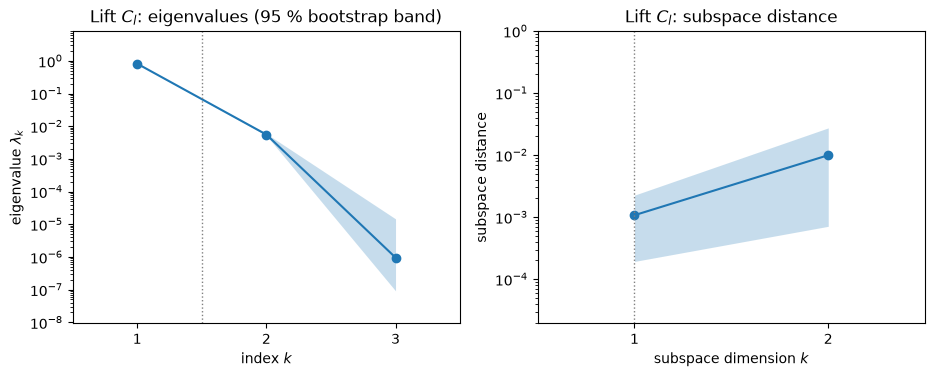

In [8]:
def eig_err_figure(s, title):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    ac.plotting.plot_eigenvalues(s, ax=a1)
    a1.set_title(f'{title}: eigenvalues (95 % bootstrap band)')
    ac.plotting.plot_subspace_errors(s, ax=a2)
    a2.set_title(f'{title}: subspace distance')
    plt.close(fig)
    print(f'{title}: mean bootstrap subspace distance, k = 1, 2:', np.array2string(ac.mean_distance(s), precision=4))
    return fig
fig = eig_err_figure(res['CL'], 'Lift $C_l$')
fig

The first eigenvalue is 147.4 times the second, and the one-dimensional subspace is very stable: the mean bootstrap distance is 0.0011 for $k = 1$ and 0.0099 for $k = 2$.

**First eigenvector.** The notebook's $w_1$ (normalized inputs) is compared with thin-airfoil theory. For a plain flap with its hinge at $x/c = 0.70$, $dC_l/d\alpha = 2\pi$ and $dC_l/d\beta = 2\pi\tau$, with $\tau = 1 - (\theta_h - \sin\theta_h)/\pi$ and $\cos\theta_h = 1 - 2\cdot0.70$. In normalized inputs each derivative is multiplied by its input's half-range (7.5° and 10°).

w1 = [ 7.9701e-01  6.0397e-01 -3.1204e-04]  95 % half-widths [8.7e-04 1.1e-03 1.8e-03]
thin airfoil: tau = 0.6607, direction [0.7503 0.661  0.    ], |w1 . w_thin| = 0.9973
flap effectiveness implied by w1: dCl/dflap / dCl/dalpha = 0.5683


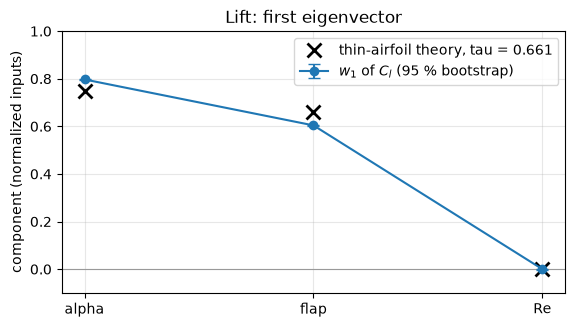

In [9]:
# thin-airfoil theory for a plain flap with hinge at x/c = 0.70: dCl/dalpha = 2 pi, dCl/dflap = 2 pi tau
th = np.arccos(1 - 2 * 0.70)
tau = 1 - (th - np.sin(th)) / np.pi
half = (hi - lo) / 2                                               # d/dx_normalized = half-range * d/dx_physical
g_thin = np.array([1.0, tau, 0.0]) * half                          # per degree, up to the common factor 2 pi
w_thin = g_thin / np.linalg.norm(g_thin)
s = res['CL']
w1 = s.eigenvectors[:, 0]
B = s.bootstrap_eigenvectors[:, :, 0]
hw = (np.percentile(B, 97.5, 0) - np.percentile(B, 2.5, 0)) / 2
tau_xfoil = (w1[1] / half[1]) / (w1[0] / half[0])
fig, ax = plt.subplots(figsize=(6.5, 3.4))
k = np.arange(3)
ax.axhline(0, color='0.6', lw=0.8)
ax.errorbar(k, w1, yerr=hw, fmt='o-', capsize=4, label='$w_1$ of $C_l$ (95 % bootstrap)')
ax.plot(k, w_thin, 'kx', ms=10, mew=2, label=f'thin-airfoil theory, tau = {tau:.3f}')
ax.set_xticks(k, ['alpha', 'flap', 'Re']); ax.set_ylabel('component (normalized inputs)')
ax.set_ylim(-0.1, 1.0); ax.grid(True, alpha=0.3); ax.legend(loc='upper right'); ax.set_title('Lift: first eigenvector')
plt.close(fig)
print('w1 =', np.array2string(w1, precision=4), ' 95 % half-widths', np.array2string(hw, formatter={'float_kind': lambda v: f'{v:.1e}'}))
print(f'thin airfoil: tau = {tau:.4f}, direction {np.array2string(w_thin, precision=4)}, |w1 . w_thin| = {abs(w1 @ w_thin):.4f}')
print(f'flap effectiveness implied by w1: dCl/dflap / dCl/dalpha = {tau_xfoil:.4f}')
fig

$w_1 = (0.797, 0.604, -0.0003)$ for (α, β, Re), with 95 % bootstrap half-widths of $1.8\times10^{-3}$ or less. The Reynolds number has no weight. Thin-airfoil theory gives $\tau = 0.661$ and the direction $(0.750, 0.661, 0)$, within $|w_1\cdot w_{thin}| = 0.9973$ of XFOIL's. The ratio of the flap and incidence components, divided by the ratio of the half-ranges, is XFOIL's average flap effectiveness: 0.568, about 14 % below the inviscid value. That is consistent with the known viscous loss of plain-flap effectiveness.

**Sufficient summary plot.** $C_l$ against $y_1 = w_1^T\mathbf x$. Red rings mark runs that converged only in a unit-step sweep, green squares runs converged by the retry ladder. Black triangles at the bottom mark the $y_1$ values of the runs that still fail.

y1 range [-1.367, 1.347];  linear fit in y1: in-sample R^2 = 0.98336, slope 0.8761 per unit y1;  remaining failures at y1 = -1.042, -1.006, 0.317
for y1 > 1.0: 42 runs, residual from the line: mean -0.1663, min -0.2740
ladder rows: residual from the line: mean -0.1037, min -0.2438, max +0.0158


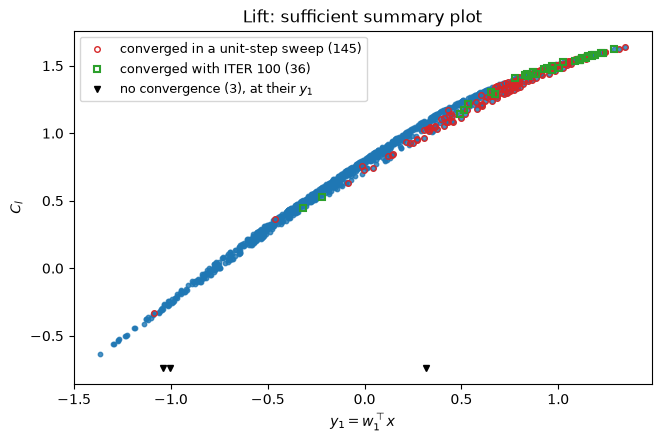

In [10]:
f = Yk[:, 0]
y = Zk @ w1
fig, ax = ac.plotting.plot_sufficient_summary(s, X=Xk, f=f, dims=1, qoi_label='$C_l$', figsize=(6.5, 4.3),
                                              scatter_kw={'color': 'C0', 's': 10})
side = (stk == 1) | (stk == 2)
ax.plot(y[side], f[side], 'o', ms=4, mfc='none', mec='C3', label=f'converged in a unit-step sweep ({side.sum()})')
lad = stk >= 3
ax.plot(y[lad], f[lad], 's', ms=5, mfc='none', mec='C2', mew=1.5, label=f'converged with ITER 100 ({lad.sum()})')
yf = (2 * (X[fail] - lo) / (hi - lo) - 1) @ w1
ax.plot(yf, np.full(yf.shape, f.min() - 0.1), 'kv', ms=5, label=f'no convergence ({fail.sum()}), at their $y_1$')
c1 = np.polyfit(y, f, 1)
ax.legend(loc='upper left', fontsize=9); ax.set_title('Lift: sufficient summary plot')
plt.close(fig)
r = f - np.polyval(c1, y)
print(f'y1 range [{y.min():.3f}, {y.max():.3f}];  linear fit in y1: in-sample R^2 = {1 - r @ r / ((f - f.mean()) @ (f - f.mean())):.5f}, '
      f'slope {c1[0]:.4f} per unit y1;  remaining failures at y1 = ' + ', '.join(f'{v:.3f}' for v in np.sort(yf)))
top = y > 1.0
print(f'for y1 > 1.0: {top.sum()} runs, residual from the line: mean {r[top].mean():+.4f}, min {r[top].min():+.4f}')
print(f'ladder rows: residual from the line: mean {r[lad].mean():+.4f}, min {r[lad].min():+.4f}, max {r[lad].max():+.4f}')
fig

$C_l$ is almost a linear function of one variable: a straight line in $y_1$ explains an in-sample $R^2 = 0.98336$, with slope 0.8761 per unit of $y_1$ over $y_1 \in [-1.367, 1.347]$. The only visible departure is at the top. The 42 runs with $y_1 > 1.0$ lie on average 0.1663 below the line, and up to 0.2740 below: the lift curve bends over towards maximum lift. The ladder runs sit on the same curve (mean residual −0.1037, since most are at high lift), as do the sweep-converged runs. The three remaining failures are at $y_1$ = −1.042, −1.006 and 0.317, away from the high-lift end.

**Where runs fail.** Failed runs are missing not at random if they cluster in one part of the input space. The next cell gives the failure rate in bins of $y_1$ (the lift variable) for the authors' protocol alone (attempts 1–3, 20 iterations) and with the retry ladder.

In [11]:
# where the runs fail: failure rate by y1 = w1(CL)^T x over all 1000 design points
from scipy import stats
yall = (2 * (X - lo) / (hi - lo) - 1) @ w1
edges = [-1.5, -1.0, -0.6, -0.2, 0.2, 0.6, 1.0, 1.5]
print('  y1 bin           points  failed attempts 1-3 (20 iterations)   failed every attempt (with the ladder)')
for a, b in zip(edges[:-1], edges[1:]):
    m = (yall >= a) & (yall < b)
    print(f'  [{a:+.1f}, {b:+.1f})   {m.sum():6d}   {np.sum(f13 & m):5d} ({np.mean(f13[m]) * 100:5.1f} %)'
          f'                       {np.sum(fail & m):5d} ({np.mean(fail[m]) * 100:4.1f} %)')
ks = [stats.kstest((X[ok, i] - lo[i]) / (hi[i] - lo[i]), 'uniform').pvalue for i in range(2)]
ks13 = [stats.kstest((X[~f13, i] - lo[i]) / (hi[i] - lo[i]), 'uniform').pvalue for i in range(2)]
print(f'KS test of the kept alpha, flap against uniform: p = {ks[0]:.2f}, {ks[1]:.2f} '
      f'(rows kept without the ladder: p = {ks13[0]:.2f}, {ks13[1]:.2f})')

  y1 bin           points  failed attempts 1-3 (20 iterations)   failed every attempt (with the ladder)
  [-1.5, -1.0)       38       2 (  5.3 %)                           2 ( 5.3 %)
  [-1.0, -0.6)      110       0 (  0.0 %)                           0 ( 0.0 %)
  [-0.6, -0.2)      237       2 (  0.8 %)                           0 ( 0.0 %)
  [-0.2, +0.2)      246       0 (  0.0 %)                           0 ( 0.0 %)
  [+0.2, +0.6)      196       4 (  2.0 %)                           1 ( 0.5 %)
  [+0.6, +1.0)      131      14 ( 10.7 %)                           0 ( 0.0 %)
  [+1.0, +1.5)       42      17 ( 40.5 %)                           0 ( 0.0 %)
KS test of the kept alpha, flap against uniform: p = 1.00, 1.00 (rows kept without the ladder: p = 0.78, 0.84)


With 20 iterations the failures cluster at high lift: 0 % for $y_1 \in [-0.2, 0.2)$, 2.0 % for $[0.2, 0.6)$, 10.7 % for $[0.6, 1.0)$ and 40.5 % (17 of 42) for $y_1 \ge 1.0$. The retained marginals of α and β still looked uniform (KS p = 0.78 and 0.84), so the gap showed only jointly. The ladder removes it: no point with $y_1 \ge 0.6$ fails, and the 3 remaining failures (0.3 %) are two in the lowest-lift bin and one in $[0.2, 0.6)$. The ladder's points are mostly the high-lift points that 20 iterations could not converge, not points past stall.

### Results: drag $C_d$ and moment $C_m$
**Eigenvalues and subspace errors.**

Drag $C_d$: mean bootstrap subspace distance, k = 1, 2: [0.0043 0.0111]


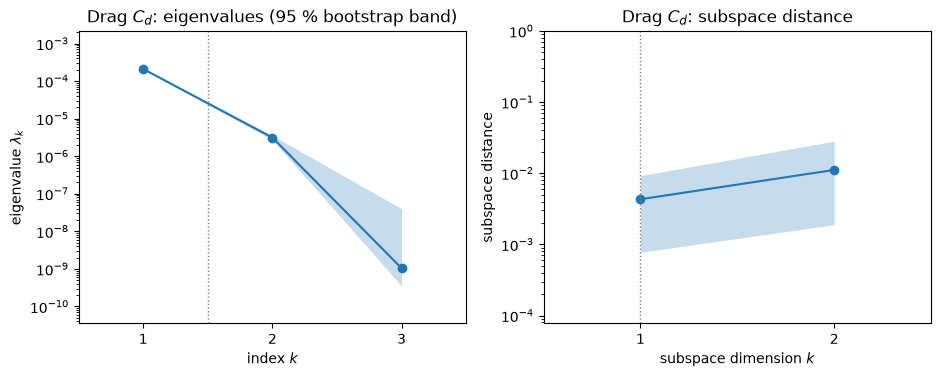

In [12]:
fig = eig_err_figure(res['CD'], 'Drag $C_d$')
fig

Moment $C_m$: mean bootstrap subspace distance, k = 1, 2: [0.003  0.0052]


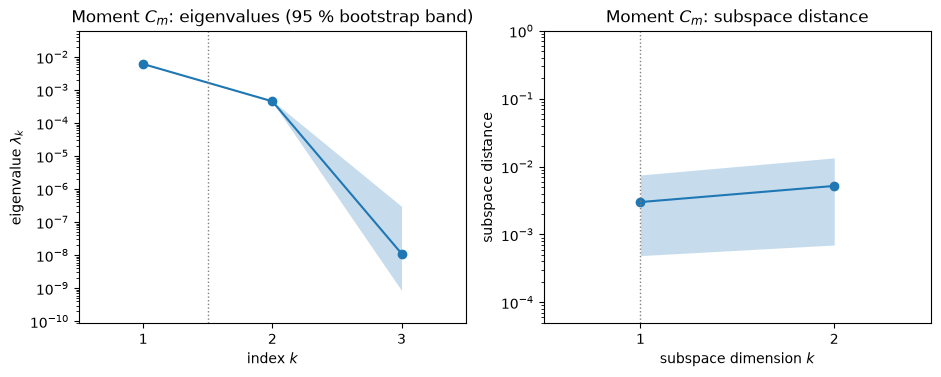

In [13]:
fig = eig_err_figure(res['CM'], 'Moment $C_m$')
fig

For $C_d$, $\lambda_1/\lambda_2 = 67.0$ and the mean bootstrap distance is 0.0043 for $k = 1$. For $C_m$, $\lambda_1/\lambda_2 = 13.4$ and the distances are 0.0030 ($k = 1$) and 0.0052 ($k = 2$). Both one-dimensional subspaces are well determined. For $C_m$ the second eigenvalue is still 7.4 % of the first, so a second direction may matter for prediction (tested below).

**Eigenvectors** with 95 % bootstrap half-widths.

CD: w1 = [0.7017 0.7124 0.0059]  95 % half-widths [4.5e-03 4.4e-03 6.7e-03]
CD: w2 = [ 0.7124 -0.7018  0.0092]  95 % half-widths [4.5e-03 4.5e-03 2.4e-02]
CM: w1 = [ 1.7510e-01 -9.8455e-01 -1.7794e-04]  95 % half-widths [6.4e-03 1.1e-03 2.8e-03]
CM: w2 = [0.9845 0.1751 0.0019]  95 % half-widths [1.1e-03 6.4e-03 1.2e-02]
|w1(CD) . w1(CL)| = 0.9896;  |w1(CM) . flap axis| = 0.9846


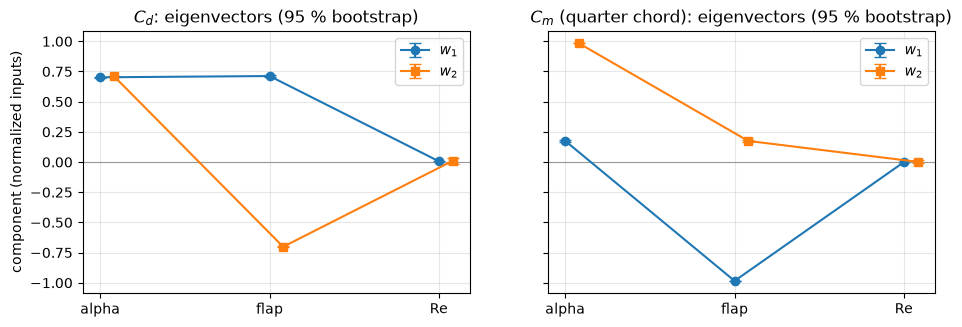

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a, q in zip(axs, ['CD', 'CM']):
    s = res[q]
    for c in range(2):
        Bq = s.bootstrap_eigenvectors[:, :, c]
        hwq = (np.percentile(Bq, 97.5, 0) - np.percentile(Bq, 2.5, 0)) / 2
        a.errorbar(k + 0.08 * c, s.eigenvectors[:, c], yerr=hwq, fmt='os'[c] + '-', capsize=4, label=f'$w_{c + 1}$')
        print(f'{q}: w{c + 1} = {np.array2string(s.eigenvectors[:, c], precision=4)}  95 % half-widths {np.array2string(hwq, formatter={"float_kind": lambda v: f"{v:.1e}"})}')
    a.axhline(0, color='0.6', lw=0.8); a.set_xticks(k, ['alpha', 'flap', 'Re']); a.grid(True, alpha=0.3)
    a.set_title(f'{labels[q]}: eigenvectors (95 % bootstrap)'); a.legend()
axs[0].set_ylabel('component (normalized inputs)')
plt.close(fig)
print(f"|w1(CD) . w1(CL)| = {abs(res['CD'].eigenvectors[:, 0] @ res['CL'].eigenvectors[:, 0]):.4f};  "
      f"|w1(CM) . flap axis| = {abs(res['CM'].eigenvectors[1, 0]):.4f}")
fig

The drag direction $w_1 = (0.702, 0.712, 0.006)$ lies within $|w_1(C_d)\cdot w_1(C_l)| = 0.9896$ of the lift direction. Drag here is mostly a function of lift, and so of the same mix of α and β. The moment direction is the flap axis, $w_1 = (0.175, -0.985, -0.0002)$: more flap gives a more nose-down moment. A small α component remains, whereas thin-airfoil theory gives none, since $C_{m,c/4}$ does not depend on α there. Its second direction is almost pure angle of attack ($w_2 = (0.985, 0.175, 0.002)$). The first eigenvectors' 95 % half-widths are at most 0.0067 ($C_d$) and 0.0064 ($C_m$).

**Sufficient summary plots.** Drag and moment against $y_1$, and the moment against $(y_1, y_2)$.

CD: polynomial of degree 1 in y1, in-sample R^2 = 0.7644
CD: polynomial of degree 2 in y1, in-sample R^2 = 0.9823
CD: polynomial of degree 3 in y1, in-sample R^2 = 0.9901
CM: polynomial of degree 1 in y1, in-sample R^2 = 0.9429
CM: polynomial of degree 2 in y1, in-sample R^2 = 0.9484
CM: polynomial of degree 3 in y1, in-sample R^2 = 0.9487
CD: minimum over the data 0.01203 at y1 = -0.729; CD at y1 > 1: median 0.03815; CD at y1 < -1: median 0.01299


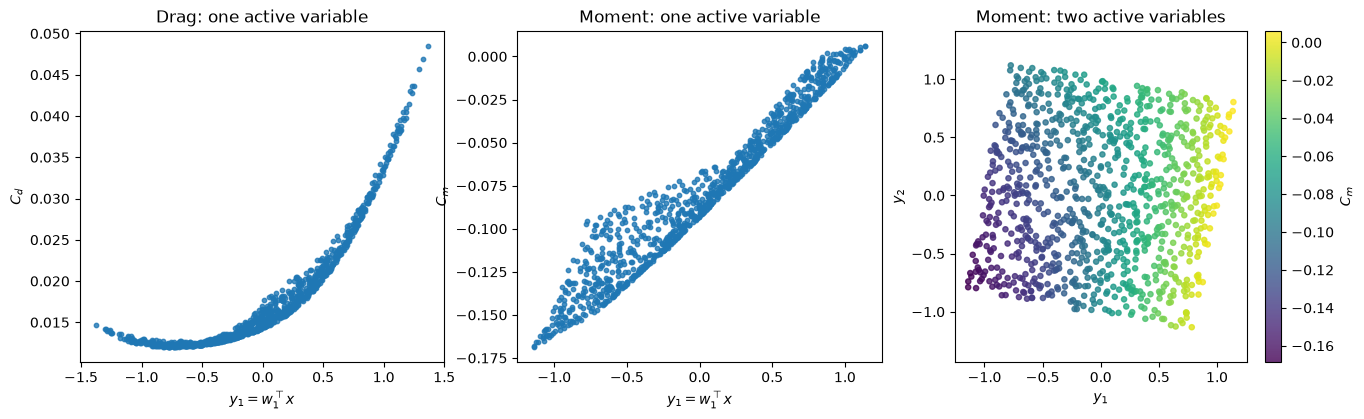

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3))
ac.plotting.plot_sufficient_summary(res['CD'], X=Xk, f=Yk[:, 1], dims=1, qoi_label='$C_d$', ax=axs[0],
                                    scatter_kw={'s': 10})
ac.plotting.plot_sufficient_summary(res['CM'], X=Xk, f=Yk[:, 3], dims=1, qoi_label='$C_m$', ax=axs[1],
                                    scatter_kw={'s': 10})
ac.plotting.plot_sufficient_summary(ac.with_dimension(res['CM'], n=2), X=Xk, f=Yk[:, 3], dims=2, qoi_label='$C_m$',
                                    ax=axs[2], scatter_kw={'cmap': 'viridis', 's': 14})
axs[0].set_title('Drag: one active variable'); axs[1].set_title('Moment: one active variable')
axs[2].set_title('Moment: two active variables')
plt.close(fig)
for q, j in [('CD', 1), ('CM', 3)]:
    yq = Zk @ res[q].eigenvectors[:, 0]
    for deg in (1, 2, 3):
        cq = np.polyfit(yq, Yk[:, j], deg)
        rq = Yk[:, j] - np.polyval(cq, yq)
        print(f'{q}: polynomial of degree {deg} in y1, in-sample R^2 = {1 - rq @ rq / ((Yk[:, j] - Yk[:, j].mean()) @ (Yk[:, j] - Yk[:, j].mean())):.4f}')
yd = Zk @ res['CD'].eigenvectors[:, 0]
print(f'CD: minimum over the data {Yk[:, 1].min():.5f} at y1 = {yd[np.argmin(Yk[:, 1])]:.3f}; CD at y1 > 1: '
      f'median {np.median(Yk[yd > 1, 1]):.5f}; CD at y1 < -1: median {np.median(Yk[yd < -1, 1]):.5f}')
fig

Drag is a curved function of one variable: a line in $y_1$ explains an in-sample $R^2$ of only 0.7644, a quadratic 0.9823 and a cubic 0.9901. This is the drag polar seen through the active variable: $C_d$ falls from a median of 0.01299 at $y_1 < -1$ to its minimum, 0.01203, at $y_1 = -0.729$, then rises to a median of 0.03815 at $y_1 > 1$. Scatter remains at large $y_1$, and a second variable removes most of it (cubic LOO $R^2$ 0.98998 with one variable, 0.99862 with two; next section). Drag there depends on how lift is made, by incidence or by flap, not only on how much. The moment is close to linear in its first variable (in-sample $R^2$ 0.9429 for a line, 0.9487 for a cubic). The scatter about that trend widens at low $y_1$, that is, at large flap deflection. The two-variable plot shows that this scatter is ordered by $y_2$ (mainly the angle of attack), which a one-variable fit cannot capture.

**How much the ratios depend on the failed runs.** The eigenvalue ratios are recomputed (same estimator, no bootstrap) four ways: the baseline (997 rows); without the 36 ladder rows, i.e. the data of the authors' protocol (961 rows); with the 3 remaining failures imputed as the quadratic's prediction plus a pessimistic shift (−0.30 for $C_l$, the largest residual below the lift line at the top; +0.010 for $C_d$ and $C_m$); and without the whole corner $\alpha > 5°$, $\beta > 10°$.

In [16]:
# how much the eigenvalue ratios depend on the rule for the runs that fail
Z_all = 2 * (X - lo) / (hi - lo) - 1
def ratio(Xs, fs):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ac.ValidityWarning)
        s_ = ac.active_subspace(space=space, X=Xs, f=fs, estimator='qphd', n=1)
    return s_.eigenvalues[0] / s_.eigenvalues[1], s_.eigenvectors[:, 0]
shift = {'CL': -0.30, 'CD': +0.010, 'CM': +0.010}   # the worst residual below the CL line at the top (above), and 0.01 for CD, CM
rob = {}
print('QoI  baseline | without the ladder rows (the old protocol) | failures imputed: quadratic + shift | drop corner alpha > 5, flap > 10')
for q, j in qois.items():
    w0 = res[q].eigenvectors[:, 0]
    base = res[q].eigenvalues[0] / res[q].eigenvalues[1]
    old = ok & (st <= 2)
    r_old, w_old = ratio(X[old], Y[old, j])
    c = AtAi @ A.T @ Yk[:, j]
    fi = Y[:, j].copy(); fi[fail] = mono(Z_all[fail]) @ c + shift[q]
    r_imp, w_imp = ratio(X, fi)
    keep = ok & ~hl
    r_cor, w_cor = ratio(X[keep], Y[keep, j])
    # the same imputation applied to the 39 failures of the old protocol (quadratic fitted to its 961 rows)
    Ao = mono(Z_all[old]); co = np.linalg.lstsq(Ao, Y[old, j], rcond=None)[0]
    fo = Y[:, j].copy(); fo[~old] = mono(Z_all[~old]) @ co + shift[q]
    r_oimp, _ = ratio(X, fo)
    rob[q] = (base, r_old, r_imp, r_cor, r_oimp)
    print(f'{q}  {base:8.1f} | {r_old:8.1f} (|w.w0| {abs(w_old @ w0):.5f}) | {r_imp:8.1f} (shift {shift[q]:+.2f}, |w.w0| {abs(w_imp @ w0):.5f})'
          f' | {r_cor:8.1f} ({keep.sum()} rows, |w.w0| {abs(w_cor @ w0):.5f})')
    print(f'      old protocol with its {np.sum(~old)} failures imputed the same way: lam1/lam2 = {r_oimp:.1f}')

QoI  baseline | without the ladder rows (the old protocol) | failures imputed: quadratic + shift | drop corner alpha > 5, flap > 10
CL     147.4 |    145.5 (|w.w0| 1.00000) |    143.7 (shift -0.30, |w.w0| 1.00000) |    151.2 (917 rows, |w.w0| 1.00000)
      old protocol with its 39 failures imputed the same way: lam1/lam2 = 119.7
CD      67.0 |     68.5 (|w.w0| 0.99999) |     69.7 (shift +0.01, |w.w0| 1.00000) |     68.2 (917 rows, |w.w0| 0.99997)
      old protocol with its 39 failures imputed the same way: lam1/lam2 = 67.6
CM      13.4 |     13.7 (|w.w0| 1.00000) |     13.4 (shift +0.01, |w.w0| 1.00000) |     13.5 (917 rows, |w.w0| 1.00000)
      old protocol with its 39 failures imputed the same way: lam1/lam2 = 11.7


The directions do not move ($|w\cdot w_0| \ge 0.99997$ in every case). The ratios move by a few percent: $C_l$ 143.7–151.2 around the baseline 147.4, $C_d$ 67.0–69.7 and $C_m$ 13.4–13.7. Before the ladder, imputing its 39 failures the same way moves $C_l$'s ratio to 119.7 (and $C_m$'s to 11.7; printed above); with the ladder, the real values at those points give 147.4, slightly more than the 145.5 obtained by dropping them. The ratios are therefore quoted as about 147, 67 and 13, not to four figures.

### Extension: transition settings as uncertain inputs (m = 6)
This section is **our extension**, not part of the paper or the challenge. The same estimator (here 28 coefficients from 1000 runs) is applied to the six-input design. The eigenvalues are shown relative to $\lambda_1$.

extension: status counts {0: 990, 1: 3, 2: 1, 4: 6} ; inputs redrawn from the seed: True
failures (alpha, flap, Re, Ncrit, xtr_top, xtr_bot): none
rows that needed the retry ladder (alpha, flap, Ncrit; status): (0.48, -0.38, 2.06; 4), (-2.00, 11.76, 3.26; 4), (2.28, 13.75, 7.12; 4), (9.86, 14.37, 3.18; 4), (3.17, -2.56, 3.83; 4), (-0.02, 10.37, 7.84; 4)
transition x/c reached: upper 0.0000-0.8969, lower 0.0001-0.9993;  CD range [0.00603, 0.04661]


CL: quadratic LOO R^2 0.9978;  lam/lam1 = [1.0000e+00 3.8547e-03 6.3339e-04 2.6507e-04 1.6105e-05 1.0430e-05];  lam1/lam2 = 259.4, lam2/lam3 = 6.09
     w1 = [ 0.773  0.634 -0.001  0.017  0.02  -0.002];  w2 = [ 0.613 -0.757 -0.02   0.151  0.167  0.026];  |w1 (first 3) . w1 (challenge)| = 0.9993


CD: quadratic LOO R^2 0.9832;  lam/lam1 = [1.0000e+00 1.7278e-02 7.5326e-03 5.2606e-03 1.0864e-04 4.9200e-05];  lam1/lam2 = 57.9, lam2/lam3 = 2.29
     w1 = [ 0.747  0.662  0.003 -0.051 -0.021 -0.023];  w2 = [-0.474  0.499  0.006 -0.194 -0.698  0.044];  |w1 (first 3) . w1 (challenge)| = 0.9977


CM: quadratic LOO R^2 0.9927;  lam/lam1 = [1.0000e+00 9.0687e-02 2.5942e-03 7.4380e-04 1.1305e-04 4.1597e-05];  lam1/lam2 = 11.0, lam2/lam3 = 34.96
     w1 = [ 0.198 -0.979  0.002 -0.03  -0.037  0.001];  w2 = [ 0.976  0.202  0.013 -0.073 -0.043 -0.013];  |w1 (first 3) . w1 (challenge)| = 0.9997


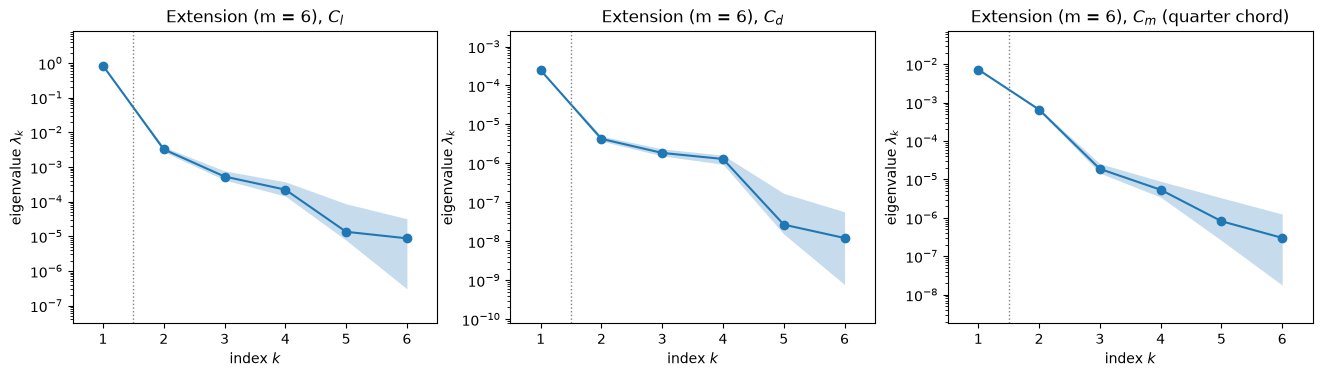

In [17]:
names_e = [b[0] for b in gd.EXTENSION_BOUNDS]
lo_e = np.array([b[2] for b in gd.EXTENSION_BOUNDS]); hi_e = np.array([b[3] for b in gd.EXTENSION_BOUNDS])
space_e = ac.Uniform(lo_e, hi_e, names=names_e)
st_e = Ye[:, 6].astype(int)
ok_e = st_e >= 0
print('extension: status counts', {int(a): int(b) for a, b in zip(*np.unique(st_e, return_counts=True))},
      '; inputs redrawn from the seed:',
      np.array_equal(Xe, gd.latin_hypercube(gd.M_EXTENSION, gd.EXTENSION_BOUNDS, gd.SEED_EXTENSION)))
print('failures (alpha, flap, Re, Ncrit, xtr_top, xtr_bot):', ('\n  ' + '\n  '.join('(' + ', '.join(f'{v:.4g}' for v in x) + ')' for x in Xe[~ok_e])) if (~ok_e).any() else 'none')
print('rows that needed the retry ladder (alpha, flap, Ncrit; status):', ', '.join(f'({x[0]:.2f}, {x[1]:.2f}, {x[3]:.2f}; {s_})' for x, s_ in zip(Xe[st_e >= 3], st_e[st_e >= 3])))
print(f'transition x/c reached: upper {Ye[ok_e, 4].min():.4f}-{Ye[ok_e, 4].max():.4f}, '
      f'lower {Ye[ok_e, 5].min():.4f}-{Ye[ok_e, 5].max():.4f};  CD range [{Ye[ok_e, 1].min():.5f}, {Ye[ok_e, 1].max():.5f}]')
res_e, quad_e = {}, {}
for q, j in qois.items():
    f = Ye[ok_e, j]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ac.ValidityWarning)
        s = ac.active_subspace(space=space_e, X=Xe[ok_e], f=f, estimator='qphd', nboot=500, bootstrap_vectors=2,
                               rng=SEED, qoi=q)
    res_e[q] = ac.orient(s, by='covariance', X=Xe[ok_e], f=f, columns=2)
    quad_e[q] = ac.fit_surrogate(X=Xe[ok_e], f=f, space=space_e, subspace=None, kind='poly', degree=2, qoi=q)
    lam = res_e[q].eigenvalues
    W = res_e[q].eigenvectors
    print(f'{q}: quadratic LOO R^2 {quad_e[q].loo_r_squared:.4f};  lam/lam1 = {np.array2string(lam / lam[0], precision=4)};  '
          f'lam1/lam2 = {lam[0] / lam[1]:.1f}, lam2/lam3 = {lam[1] / lam[2]:.2f}')
    print(f'     w1 = {np.array2string(W[:, 0], precision=3)};  w2 = {np.array2string(W[:, 1], precision=3)};  '
          f'|w1 (first 3) . w1 (challenge)| = {abs(W[:3, 0] @ res[q].eigenvectors[:, 0]) / np.linalg.norm(W[:3, 0]):.4f}')
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
for a, q in zip(axs, qois):
    ac.plotting.plot_eigenvalues(res_e[q], ax=a)
    a.set_title(f'Extension (m = 6), {labels[q]}')
plt.close(fig)
fig

In the extension all 1000 runs converge: 990 directly, 4 in a unit-step sweep (3 the authors', 1 ours) and 6 in the retry ladder's continuation. The 6 that failed with 20 iterations all have $N_{crit} \ge 2.0$; five are at moderate lift and one at (9.86°, 14.37°). Transition now moves as far back as $x/c = 0.8969$ on the upper surface and 0.9993 on the lower. That is why these runs converge more often than the challenge's: with $N_{crit} = 0.01$ transition sits at the leading edge ($x/c \le 0.0419$), where XFOIL's Newton iteration struggles (in the trace of the failed challenge point at (−2.46°, −2.94°), the largest residual is at boundary-layer station 3 in every one of the 20 iterations; DATA.md). The leading directions are unchanged: the first three components of $w_1$ match the challenge study's $w_1$ to 0.9993 ($C_l$), 0.9977 ($C_d$) and 0.9997 ($C_m$). The transition settings get at most 0.051 of weight in any $w_1$. The first gaps stay large: $\lambda_1/\lambda_2$ = 259.4 for $C_l$, 57.9 for $C_d$ and 11.0 for $C_m$. For $C_m$ the second direction is again the angle of attack; for $C_l$ and $C_d$ the second directions include the transition settings (below). The quadratic in six inputs has LOO $R^2$ = 0.9978, 0.9832 and 0.9927.

CD, w2 95 % half-widths: [0.082 0.098 0.051 0.137 0.115 0.076]
CD with |y1| < 0.1: Ncrit < 1 median 0.01253 (9 runs), Ncrit > 8 median 0.00996 (12 runs)


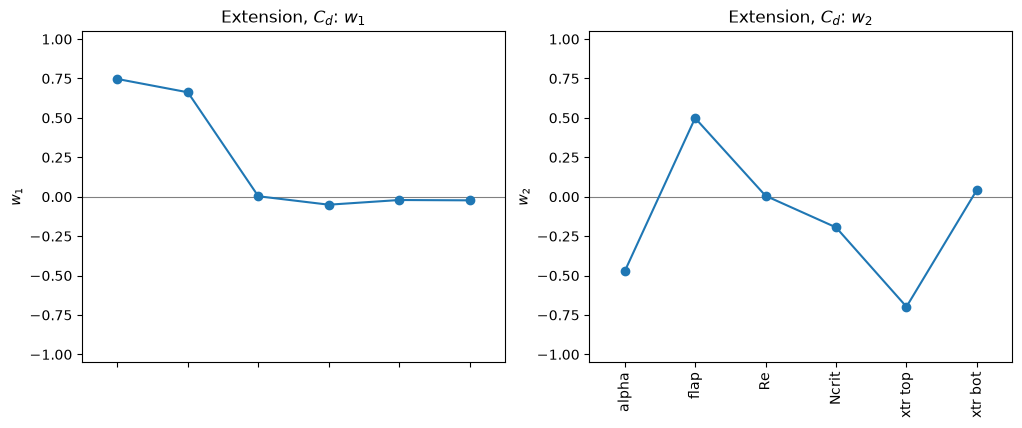

In [18]:
s = res_e['CD']
f = Ye[ok_e, 1]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
ac.plotting.plot_eigenvectors(s, indices=[0, 1], labels=['alpha', 'flap', 'Re', 'Ncrit', 'xtr top', 'xtr bot'], ax=axs)
axs[0].set_title('Extension, $C_d$: $w_1$'); axs[1].set_title('Extension, $C_d$: $w_2$')
plt.close(fig)
B2 = s.bootstrap_eigenvectors[:, :, 1]
print('CD, w2 95 % half-widths:', np.array2string((np.percentile(B2, 97.5, 0) - np.percentile(B2, 2.5, 0)) / 2, precision=3))
# the transition settings at fixed operating condition: compare low and high Ncrit in a narrow alpha-flap band
yc = (2 * (Xe[ok_e] - lo_e) / (hi_e - lo_e) - 1) @ s.eigenvectors[:, 0]
band = np.abs(yc) < 0.1
lowN, highN = band & (Xe[ok_e, 3] < 1.0), band & (Xe[ok_e, 3] > 8.0)
print(f'CD with |y1| < 0.1: Ncrit < 1 median {np.median(f[lowN]):.5f} ({lowN.sum()} runs), '
      f'Ncrit > 8 median {np.median(f[highN]):.5f} ({highN.sum()} runs)')
fig

For drag the second direction mixes the upper-surface trip location (−0.698) with the operating conditions (−0.474, 0.499) and $N_{crit}$ (−0.194). Its bootstrap half-widths are 0.05–0.14, so $w_2$ is only roughly determined, and $\lambda_2/\lambda_3 = 2.29$ gives no clean second gap. The transition settings do matter for drag at a fixed operating condition. Among runs near the middle of the first active variable ($|y_1| < 0.1$), the median $C_d$ is 0.01253 for $N_{crit} < 1$ (9 runs) and 0.00996 for $N_{crit} > 8$ (12 runs): about 20 % less drag, consistent with laminar flow over more of the chord. Over the whole envelope, though, that effect is small next to the change of drag with lift. The variance along $w_2$ is 1.7 % of that along $w_1$.

### Surrogates on the active variables
Polynomials of degree 1–4 in $n = 1$ or $2$ active variables of the challenge study, with leave-one-out (LOO) $R^2$. The subspaces are held fixed at the quadratic estimates, so the LOO values do not include the error of estimating them. The plots show one chosen fit for each QoI.

QoI  n  degree  LOO R^2
CL   1     1   0.98324
CL   1     2   0.99665
CL   1     3   0.99714
CL   1     4   0.99714
CL   2     1   0.98353
CL   2     2   0.99921
CL   2     3   0.99974
CL   2     4   0.99996
CD   1     1   0.76254
CD   1     2   0.98206
CD   1     3   0.98998
CD   1     4   0.99095
CD   2     1   0.76239
CD   2     2   0.98874
CD   2     3   0.99862
CD   2     4   0.99940
CM   1     1   0.94265
CM   1     2   0.94808
CM   1     3   0.94827
CM   1     4   0.95115
CM   2     1   0.95184
CM   2     2   0.99812
CM   2     3   0.99868
CM   2     4   0.99975


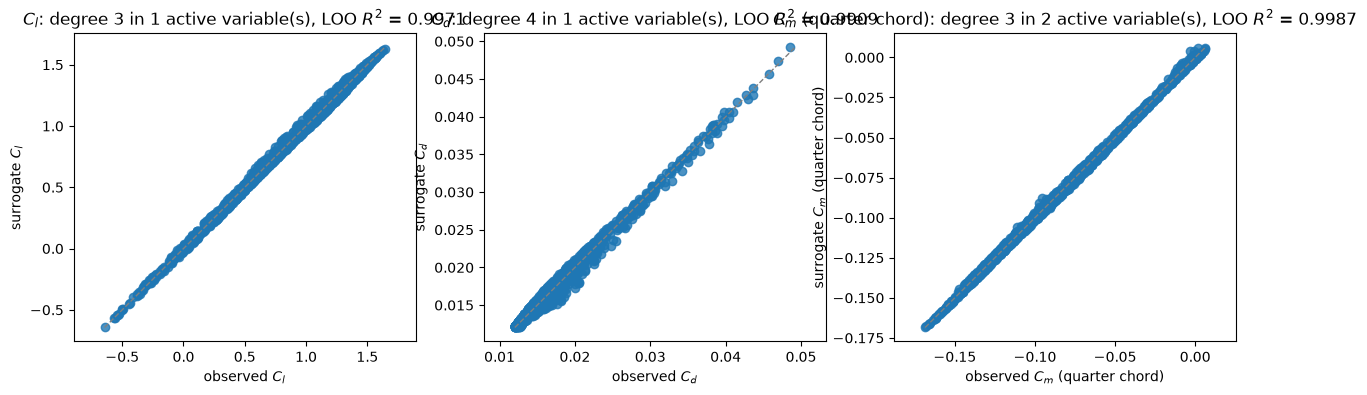

In [19]:
rows = []
sur = {}
for q, j in qois.items():
    for n in (1, 2):
        for deg in (1, 2, 3, 4):
            g = ac.fit_surrogate(X=Xk, f=Yk[:, j], subspace=ac.with_dimension(res[q], n=n), kind='poly', degree=deg)
            sur[q, n, deg] = g
            rows.append((q, n, deg, g.loo_r_squared))
print('QoI  n  degree  LOO R^2')
for q, n, deg, r2 in rows:
    print(f'{q:3s} {n:2d} {deg:5d}   {r2:.5f}')
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for a, (q, n, deg) in zip(axs, [('CL', 1, 3), ('CD', 1, 4), ('CM', 2, 3)]):
    j = qois[q]
    ac.plotting.plot_surrogate_fit(sur[q, n, deg], X=Xk, f=Yk[:, j], qoi_label=labels[q], ax=a)
    a.set_title(f'{labels[q]}: degree {deg} in {n} active variable(s), LOO $R^2$ = {sur[q, n, deg].loo_r_squared:.4f}')
plt.close(fig)
fig

One variable suffices for lift: a cubic in $y_1$ has LOO $R^2 = 0.99714$, against 0.98324 for a line. With two variables a cubic reaches 0.99974, so a little of the curvature near stall depends on the mix of incidence and flap. Drag in one variable reaches LOO 0.99095 (quartic), and a second variable raises the cubic to 0.99862. The moment needs two variables: in one it stops at 0.95115 whatever the degree, while a quadratic in two variables gives 0.99812. So we choose $n = 1$ for $C_l$ and $n = 2$ for $C_m$. For $C_d$, $n = 1$ leaves 0.9 % of the variance unexplained (LOO), and $n = 2$ is needed to explain more. Since $y_1$ and $y_2$ together span essentially the whole (α, β) plane, a two-variable surrogate here is a surrogate on all the inputs that matter.

### Comparison with the paper
The paper reports no active subspace, so the comparison is with its XFOIL setup and data. First, our XFOIL against the authors' own training file: the same inputs, rerun with our build, and the authors' 98 rows given to the same estimator.

In [20]:
st_d = Dr[:, 6].astype(int)
okd = st_d >= 0
dd = Dr[okd][:, [0, 1, 3]] - Dv[okd][:, 3:6]
same = [np.mean(np.round(Dv[okd, 3 + i], p) == Dr[okd, c]) for i, (c, p) in enumerate([(0, 4), (1, 5), (3, 4)])]
print(f"authors' 98 inputs rerun: status {dict(zip(*[a.tolist() for a in np.unique(st_d, return_counts=True)]))}; "
      f"failed here at (alpha, flap): {', '.join(f'({a:.2f}, {b:.2f})' for a, b in Dv[~okd][:, 1:3])}")
print(f'  |difference| CL: median {np.median(abs(dd[:, 0])):.1e}, max {abs(dd[:, 0]).max():.1e};  '
      f'CD: median {np.median(abs(dd[:, 1])):.1e}, max {abs(dd[:, 1]).max():.1e};  '
      f'CM: median {np.median(abs(dd[:, 2])):.1e}, max {abs(dd[:, 2]).max():.1e}')
print(f"  authors' value rounded to XFOIL's printed digits equals ours: CL {same[0]:.0%}, CD {same[1]:.0%}, CM {same[2]:.0%}")
lr = Dr[okd, 6] >= 3
print("  rows converged by the retry ladder (alpha, flap; ours - authors' CL, CD, CM):",
      ', '.join(f'({x[1]:.2f}, {x[2]:.2f}; {d[0]:+.4f}, {d[1]:+.5f}, {d[2]:+.4f})' for x, d in zip(Dv[okd][lr], dd[lr])))
big = np.argsort(-abs(dd[:, 0]))[:3]
print('  largest CL differences at (alpha, flap):', ', '.join(f'({Dv[okd][i, 1]:.2f}, {Dv[okd][i, 2]:.2f})' for i in big),
      'status', Dr[okd][big, 6].astype(int).tolist())
# which Re range did the authors' Latin hypercube use? Count the strata of a 100-point design that their 98 rows occupy
for lab, (a, b) in [('code, +-0.5 %', (696500, 703500)), ('paper p. 3, +-5 %', (665000, 735000))]:
    k = np.floor((Dv[:, 0] - a) / (b - a) * 100).astype(int)
    print(f"  Re strata of a 100-point LHS on [{a}, {b}] ({lab}) holding the authors' 98 rows: {len(np.unique(k))}")
print(f"  alpha and flap strata: {len(np.unique(np.floor((Dv[:, 1] + 5) / 15 * 100)))}, {len(np.unique(np.floor((Dv[:, 2] + 5) / 20 * 100)))}")
# quadratic-fit active subspace of the authors' 98 rows, against ours (same estimator, same space)
Xd = np.clip(Dv[:, [1, 2, 0]], lo, hi)
for q, c in [('CL', 3), ('CD', 4), ('CM', 5)]:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ac.ValidityWarning)
        sd = ac.active_subspace(space=space, X=Xd, f=Dv[:, c], estimator='qphd', n=1)
    print(f"  {q}: authors' 98 rows give w1 = {np.array2string(sd.eigenvectors[:, 0] * np.sign(sd.eigenvectors[:, 0] @ res[q].eigenvectors[:, 0]), precision=4)}, "
          f"|w1 . w1 (ours)| = {abs(sd.eigenvectors[:, 0] @ res[q].eigenvectors[:, 0]):.5f}, lam1/lam2 = {sd.eigenvalues[0] / sd.eigenvalues[1]:.0f}")

authors' 98 inputs rerun: status {-1: 1, 0: 83, 1: 12, 2: 1, 4: 1}; failed here at (alpha, flap): (7.94, 10.42)
  |difference| CL: median 5.1e-05, max 2.3e-03;  CD: median 3.6e-06, max 1.9e-04;  CM: median 3.8e-05, max 2.8e-04
  authors' value rounded to XFOIL's printed digits equals ours: CL 48%, CD 71%, CM 69%
  rows converged by the retry ladder (alpha, flap; ours - authors' CL, CD, CM): (5.04, 11.20; +0.0003, -0.00002, +0.0000)
  largest CL differences at (alpha, flap): (9.71, 14.95), (7.17, 14.44), (-4.19, 10.67) status [1, 1, 0]
  Re strata of a 100-point LHS on [696500, 703500] (code, +-0.5 %) holding the authors' 98 rows: 98
  Re strata of a 100-point LHS on [665000, 735000] (paper p. 3, +-5 %) holding the authors' 98 rows: 10
  alpha and flap strata: 98, 98
  CL: authors' 98 rows give w1 = [ 0.7984  0.6021 -0.0045], |w1 . w1 (ours)| = 0.99999, lam1/lam2 = 158
  CD: authors' 98 rows give w1 = [ 0.6962  0.7179 -0.0038], |w1 . w1 (ours)| = 0.99992, lam1/lam2 = 59
  CM: authors' 9

At the authors' 98 inputs, our XFOIL converges at 97. It fails at (7.94°, 10.42°), a high-lift point the authors converged. The point (5.04°, 11.20°), which failed with 20 iterations, converges in the retry ladder's continuation and agrees with the authors' value to $+0.0003$ in $C_l$, $-0.00002$ in $C_d$ and $+0.0000$ in $C_m$ (printed digits), which supports the ladder. The median differences are $5.1\times10^{-5}$ in $C_l$, $3.6\times10^{-6}$ in $C_d$ and $3.8\times10^{-5}$ in $C_m$, that is, at XFOIL's printed digits. The largest, $2.3\times10^{-3}$ in $C_l$, is at (9.71°, 14.95°), a sweep-converged point in the high-lift corner; the next two are at (7.17°, 14.44°), also sweep-converged, and (−4.19°, 10.67°). The authors' file holds 16 significant digits while XFOIL's polar file prints 4 (or 5). Rounded to those digits, their values equal ours for 48 % ($C_l$), 71 % ($C_d$) and 69 % ($C_m$) of the rows, so their build of XFOIL (the code calls `xfoil.exe`, presumably the MIT Windows binary) differs from ours in the last printed digit. **The Reynolds range of their design:** their 98 rows fall in 98 different Re strata of a 100-point Latin hypercube on the code's ±0.5 % range, as they do in α and β, but in only 10 strata on the paper's printed ±5 %. Their design was drawn on ±0.5 %. The active subspace is not sensitive to any of this: from the authors' 98 rows the same estimator gives first directions within 0.99999 ($C_l$), 0.99992 ($C_d$) and 0.99991 ($C_m$) of ours, with gaps 158, 59 and 16. Ours are 147.4, 67.0 and 13.4, from 997 runs.

Second, XFOIL against the challenge's truth data: at the 7 calibration points of Table 1, which the paper calibrates its XFOIL surrogate against with a discrepancy GP, and at the 4 prediction points, whose truth intervals were released after the challenge.

In [21]:
# Table 1 (p. 2): truth data at the 7 calibration points (centroids; intervals +-0.009, +-0.0008, +-0.008)
table1 = np.array([[0, 0, 0.214, 0.0121, -0.047], [5, 0, 0.737, 0.0143, -0.043], [10, 0, 1.209, 0.0205, -0.033],
                   [0, 5, 0.536, 0.0131, -0.094], [0, 10, 0.836, 0.0157, -0.137], [5, 5, 1.041, 0.0176, -0.087],
                   [-5, -5, -0.644, 0.0148, -0.004]])
cal = Ref[Ref[:, 0] == 0]
assert np.array_equal(cal[:, 1:3], table1[:, :2])
print(' alpha  flap |  CL truth  XFOIL  |  CD truth   XFOIL   |  CM truth  XFOIL  | status')
for t, r in zip(table1, cal):
    print(f'{t[0]:6.0f} {t[1]:5.0f} | {t[2]:8.3f} {r[4]:7.4f} | {t[3]:8.4f} {r[5]:8.5f} | {t[4]:8.3f} {r[7]:7.4f} | {int(r[10])}')
dl = cal[:, [4, 5, 7]] - table1[:, 2:]
print(f'XFOIL - truth: CL mean {dl[:, 0].mean():+.4f} (max |.| {abs(dl[:, 0]).max():.4f}), '
      f'CD mean {dl[:, 1].mean():+.5f}, CM mean {dl[:, 2].mean():+.4f} (max |.| {abs(dl[:, 2]).max():.4f})')
print(f'outside the truth intervals: CL {np.sum(abs(dl[:, 0]) > 0.009)}, CD {np.sum(abs(dl[:, 1]) > 0.0008)}, '
      f'CM {np.sum(abs(dl[:, 2]) > 0.008)} of 7')
# released truth intervals at the 4 prediction points: centre and half-width for CL, CD, CM, digitized by the
# authors from Figs. 2-5 of Cary et al. (uq_challenge_ground_truth_epistemic_bounds.xlsx in their repository)
truth_pred = {(0, 0): [(0.213994, 0.008983), (0.012102, 0.000796), (-0.047003, 0.007993)],
              (2, 2): [(0.572414, 0.008961), (0.013022, 0.000786), (-0.066964, 0.008995)],
              (7, 15): [(1.533508, 0.008787), (0.037162, 0.000897), (-0.118417, 0.008976)],
              (-3, -3): [(-0.323281, 0.008984), (0.012869, 0.000782), (-0.018393, 0.008991)]}
pred = Ref[Ref[:, 0] == 1]
print(' alpha  flap |  CL truth        XFOIL  |  CD truth          XFOIL   |  CM truth         XFOIL  | status')
nout = np.zeros(3, int)
for r in pred:
    t = truth_pred[int(r[1]), int(r[2])]
    v = r[[4, 5, 7]]
    out = [abs(v[i] - t[i][0]) > t[i][1] for i in range(3)]
    nout += out
    print(f'{r[1]:6.0f} {r[2]:5.0f} | {t[0][0]:7.4f}+-{t[0][1]:.4f} {v[0]:7.4f}{"*" if out[0] else " "} | '
          f'{t[1][0]:7.5f}+-{t[1][1]:.5f} {v[1]:8.5f}{"*" if out[1] else " "} | {t[2][0]:7.4f}+-{t[2][1]:.4f} {v[2]:7.4f}{"*" if out[2] else " "} | {int(r[10])}')
print(f'outside the released intervals (*): CL {nout[0]}, CD {nout[1]}, CM {nout[2]} of 4')

 alpha  flap |  CL truth  XFOIL  |  CD truth   XFOIL   |  CM truth  XFOIL  | status
     0     0 |    0.214  0.2175 |   0.0121  0.01214 |   -0.047 -0.0481 | 0
     5     0 |    0.737  0.7584 |   0.0143  0.01412 |   -0.043 -0.0450 | 0
    10     0 |    1.209  1.2300 |   0.0205  0.02031 |   -0.033 -0.0327 | 0
     0     5 |    0.536  0.5530 |   0.0131  0.01306 |   -0.094 -0.0966 | 0
     0    10 |    0.836  0.8105 |   0.0157  0.01556 |   -0.137 -0.1299 | 0
     5     5 |    1.041  1.0530 |   0.0176  0.01665 |   -0.087 -0.0860 | 0
    -5    -5 |   -0.644 -0.6730 |   0.0148  0.01490 |   -0.004 -0.0006 | 0
XFOIL - truth: CL mean +0.0029 (max |.| 0.0290), CD mean -0.00019, CM mean +0.0009 (max |.| 0.0071)
outside the truth intervals: CL 6, CD 1, CM 0 of 7
 alpha  flap |  CL truth        XFOIL  |  CD truth          XFOIL   |  CM truth         XFOIL  | status
     0     0 |  0.2140+-0.0090  0.2175  | 0.01210+-0.00080  0.01214  | -0.0470+-0.0080 -0.0481  | 0
     2     2 |  0.5724+-0.0090  0.57

XFOIL is close to the truth data but not within its intervals for lift. At the calibration points $C_l$ differs by up to 0.0290 and lies outside the ±0.009 interval at 6 of the 7 points. $C_d$ is within ±0.0008 at 6 of 7, and $C_m$ within ±0.008 at all 7. This is the model-form discrepancy that motivates the paper's Kennedy–O'Hagan correction $g(\mathbf x) = f_X(\mathbf x) + \delta(\mathbf x)$ (Eq. 2, p. 5). At the four prediction points XFOIL converges at all four, and the high-lift point (7°, 15°) needs the authors' sweep. Against the released intervals (digitized by the authors from Figs. 2–5 of Cary et al. [[2]][R2]; `uq_challenge_ground_truth_epistemic_bounds.xlsx` in their repository), XFOIL is inside all three intervals at (0°, 0°), (2°, 2°) and (−3°, −3°). At (7°, 15°) it is outside for $C_l$ (1.5155 against 1.5335 ± 0.0088) and $C_d$ (0.03808 against 0.03716 ± 0.00090), and inside for $C_m$.

| quantity | paper (or the authors' code) | notebook |
|---|---|---|
| XFOIL version | 6.99, Windows `xfoil.exe` (code) | 6.99, built from Ubuntu's source package `6.99.dfsg+1-3`, gfortran 13.3, double precision (`DATA.md`) |
| panels, $N_{crit}$, Mach | 100 (p. 3); 0.01 and 0 (code only) | 100, 0.01, 0 |
| viscous iterations | XFOIL's default, 20 (code) | 20; 100 in our retry ladder (only for points that fail with 20) |
| angle of attack, flap range | −5° to 10°, −5° to 15° (p. 3) | same |
| Reynolds range | 665,000–735,000 (p. 3); 696,500–703,500 (code; Tables 3–5, p. 23; Table 1 ± 3500) | 696,500–703,500; the authors' 98 rows fill 98 of 100 strata on it, 10 on ±5 % |
| Re effect on $C_l$, (5°, 5°) | not reported | XFOIL: +0.0004 over ±0.5 %, +0.0043 over ±5 %; quadratic fit: $-2.1\times10^{-3} \pm 1.7\times10^{-3}$ (unresolved) |
| design | 100-point Latin hypercube, seed not given (p. 3) | 1000-point Latin hypercube, seed 2412 |
| non-converged runs | not reported; 98 rows from 100 (code, inferred) | 39 of 1000 with 20 iterations; 3 (0.3 %) with the retry ladder; 1 of the authors' 98 inputs |
| XFOIL at the authors' 98 inputs | their file | median difference $5.1\times10^{-5}$ ($C_l$), max $2.3\times10^{-3}$ |
| XFOIL vs truth at Table 1 points | not reported (Table 1 gives truth only) | $C_l$ outside ±0.009 at 6 of 7; $C_m$ within ±0.008 at 7 of 7 |
| XFOIL vs released truth at the 4 prediction points | not reported (Figs. 5–8 show GP predictions) | inside all intervals at 3 points; at (7°, 15°) $C_l$ 1.5155 vs 1.5335 ± 0.0088 and $C_d$ outside |
| active subspace, $\lambda_1/\lambda_2$ | not reported | about 147 ($C_l$), 67 ($C_d$), 13 ($C_m$) (147.4, 67.0, 13.4; within 4 % under other rules for failed runs) |
| first direction (α, β, Re) | not reported | $C_l$: (0.797, 0.604, −0.0003); $C_m$: (0.175, −0.985, −0.0002) |
| XFOIL GP validation (Fig. 4) | held-out 100 points; figure only | not reproduced (no GP here); a quadratic in the 3 inputs has LOO $R^2$ 0.99921 ($C_l$) |

### References
[R1]: https://doi.org/10.48550/arXiv.2606.28871
[R2]: https://doi.org/10.2514/6.2026-0091
[R3]: https://doi.org/10.1007/978-3-642-84010-4_1
[R4]: https://doi.org/10.1137/1.9781611973860
[R5]: https://doi.org/10.1137/130916138
[R6]: https://doi.org/10.1080/01621459.1992.10476258

[1] G. Davis and A. Renganathan, "A Bayesian latent Gaussian process framework for aerodynamic uncertainty quantification", arXiv preprint arXiv:2606.28871 [stat.ML], 2026. [doi:10.48550/arXiv.2606.28871][R1] (preprint; submitted to AIAA Journal according to the authors' repository, `paper/aiaa_journal_submission`, 2026-06-26; not yet published). Code and data: [github.com/csdlpsu/uqchallenge2](https://github.com/csdlpsu/uqchallenge2), commit `73eaec9`.

[2] A. W. Cary, M. Rumpfkeil, P. O. Hristov and J. A. Schaefer, "Summary of the Second AIAA Uncertainty Quantification Challenge Problem for Aerodynamics", AIAA SCITECH 2026 Forum, AIAA 2026-0091, 2026. [doi:10.2514/6.2026-0091][R2]

[3] M. Drela, "XFOIL: An Analysis and Design System for Low Reynolds Number Airfoils", in *Low Reynolds Number Aerodynamics*, Lecture Notes in Engineering, Springer, Berlin, Heidelberg, 1989, pp. 1–12. [doi:10.1007/978-3-642-84010-4_1][R3]

[4] P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860][R4]

[5] P. G. Constantine, E. Dow and Q. Wang, "Active subspace methods in theory and practice: applications to kriging surfaces", *SIAM Journal on Scientific Computing* 36(4):A1500–A1524, 2014. [doi:10.1137/130916138][R5]

[6] K.-C. Li, "On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma", *Journal of the American Statistical Association* 87(420):1025–1039, 1992. [doi:10.1080/01621459.1992.10476258][R6]

### Acknowledgments
The paper's work "was funded by the Penn State Institute of Computational and Data Sciences (ICDS) Junior Researcher Collaboration grant", and the authors acknowledge Penn State ICDS for access to the Roar Core Facility (p. 23). XFOIL is by Mark Drela and Harold Youngren, MIT, distributed under the GNU GPL. It is used here as an outside program; none of its code is in this directory.

In [22]:
print(f'notebook run time: {time.perf_counter() - t_start:.1f} s')

notebook run time: 16.3 s
